# PROYECTO 3: PREDICCIÓN DE RESULTADOS DE FÚTBOL MEDIANTE UNA RED NEURONAL PROFUNDA (DEEP MLP)
### *Modelado Multiclase, Prevención de Fuga de Información y Calibración Probabilística en la English Premier League (EPL)*

---
**Institución:** Escuela Colombiana de Ingeniería Julio Garavito  
**Departamento:** Departamento de Ingeniería de Sistemas  
**Curso:** Principios y Tecnologías de Inteligencia Artificial (PTIA)  
**Grupo:** Grupo 04  
**Integrantes:**  
- Juan Diego Gaitán  
- José Alejandro Martínez  
- Oscar David Lasso  
- Carlos Andrés Sánchez  

**Fecha:** Octubre 2026  

**Datasets Integrados (Fusión de las 3 Fuentes Tabulares del Proyecto):**  
- **Fuente 1:** `English Premier League Match Data (2000-2025)/epl_final.csv` (Historial oficial de 9.380 partidos, goles, tiros y tarjetas)  
- **Fuente 2:** `Premier League (1993 - Present)/PremierLeague.csv` (Cuotas de apuestas Bet365 y probabilidades implícitas de mercado)  
- **Fuente 3:** `Club Football Match Data (2000 - 2026)/Matches.csv` (Calificaciones Elo dinámicas, rachas Form3/Form5 y cuotas de respaldo)  

---

### Objetivo General
Desarrollar, entrenar y evaluar rigurosamente una **Red Neuronal Artificial Profunda (Multilayer Perceptron - Deep MLP)** para la predicción del resultado de partidos de fútbol profesional en la *English Premier League* (EPL) a partir de tres clases mutuamente excluyentes:
- **Victoria Local ($H$):** El equipo de referencia (local) gana el encuentro.
- **Empate ($D$):** Ambos equipos finalizan con igual marcador.
- **Derrota Local / Victoria Visitante ($A$):** El equipo visitante gana el encuentro.

El modelo estima un vector de probabilidades  mediante la función de activación **Softmax**, garantizando que la suma de probabilidades sea aproximadamente el 100%, evaluando tanto la exactitud de clasificación como la fiabilidad probabilística.

## 1. Contexto del Proyecto y Transición desde el Perceptrón Simple

### 1.1 Salto Metodológico al Deep Learning
En este Proyecto 3 implementamos un salto cualitativo:
1. **Arquitectura Profunda No Lineal:** Redes multicapa con activaciones **ReLU** ($f(z) = \max(0, z)$), normalización por lotes (**Batch Normalization**), regularización **Dropout** y decaimiento de pesos **$L_2$**.
2. **Causalidad Temporal Estricta:** Todas las variables de entrada se calculan con datos estrictamente anteriores al pitazo inicial de cada encuentro.
3. **Partición Cronológica Estricta:** Entrenamiento en las primeras 17 temporadas (2000–2017), validación en 4 temporadas (2017–2021) y prueba final reservada en las 4 temporadas contemporáneas (2021–2025).

## 2. Fundamentos Teóricos del Aprendizaje Profundo

### 2.1 La Neurona Artificial y la Combinación Afín
Cada neurona en una capa oculta $l$ calcula una combinación afín de las activaciones de la capa previa $\mathbf{a}^{[l-1]}$:
$$z_j^{[l]} = \sum_{i=1}^{n^{[l-1]}} w_{ji}^{[l]} a_i^{[l-1]} + b_j^{[l]} \implies \mathbf{z}^{[l]} = \mathbf{W}^{[l]} \mathbf{a}^{[l-1]} + \mathbf{b}^{[l]}$$

### 2.2 Función de Activación ReLU y el Efecto Compuerta
La función de activación Rectified Linear Unit (ReLU) introduce no linealidad en el espacio latente:
$$a_j^{[l]} = \text{ReLU}(z_j^{[l]}) = \max(0, z_j^{[l]}), \quad \frac{\partial a_j^{[l]}}{\partial z_j^{[l]}} = \begin{cases} 1 & \text{si } z_j^{[l]} > 0 \\ 0 & \text{si } z_j^{[l]} \le 0 \end{cases}$$
ReLU actúa como una **compuerta condicional**: propaga el gradiente sin atenuación cuando está activa ($z > 0$), eliminando el problema de desvanecimiento del gradiente (*vanishing gradient*) característico de las funciones sigmoide y tangente hiperbólica.

### 2.3 Capa de Salida Softmax y Distribución Multiclase
Para clasificación multiclase con $C=3$ clases mutuamente excluyentes, la capa final aplica la transformación Softmax:
$$\hat{p}_c = \frac{e^{z_c^{[L]}}}{\sum_{k=1}^C e^{z_k^{[L]}}}, \quad c \in \{0, 1, 2\}$$
Softmax normaliza los logits $\mathbf{z}^{[L]}$ en un símil de probabilidades estocásticas donde $0 < \hat{p}_c < 1$ y $\sum_{c=0}^2 \hat{p}_c = 1$.

### 2.4 Función de Pérdida: Entropía Cruzada Categórica
La pérdida mide la discrepancia entre la distribución observada $\mathbf{y}$ (one-hot) y la predicha $\mathbf{\hat{y}}$:
$$\mathcal{L}_{CE}(\mathbf{y}, \mathbf{\hat{y}}) = -\sum_{c=0}^2 y_c \log(\hat{p}_c)$$

### 2.5 Retropropagación del Error (*Backpropagation*) y Regla de la Cadena
En la pasada hacia atrás, el error en la capa de salida para Softmax con Entropía Cruzada se simplifica elegantemente a:
$$\boldsymbol{\delta}^{[L]} = \frac{\partial \mathcal{L}}{\partial \mathbf{z}^{[L]}} = \mathbf{\hat{y}} - \mathbf{y}$$
Para las capas ocultas intermedias $l = L-1, \dots, 1$, el error se propaga hacia atrás mediante la transpuesta de la matriz de pesos y la derivada de la activación:
$$\boldsymbol{\delta}^{[l]} = \left( (\mathbf{W}^{[l+1]})^T \boldsymbol{\delta}^{[l+1]} \right) \odot \text{ReLU}'(\mathbf{z}^{[l]})$$
Los gradientes de los pesos y sesgos corresponden a:
$$\frac{\partial \mathcal{L}}{\partial \mathbf{W}^{[l]}} = \boldsymbol{\delta}^{[l]} (\mathbf{a}^{[l-1]})^T, \quad \frac{\partial \mathcal{L}}{\partial \mathbf{b}^{[l]}} = \boldsymbol{\delta}^{[l]}$$

### 2.6 Optimización con Adam
Adam mantiene promedios móviles exponenciales de los gradientes (momento de primer orden $m_t$) y de los cuadrados de los gradientes (momento de segundo orden $v_t$):
$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t, \quad v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2$$
Corrigiendo el sesgo inicial ($\hat{m}_t = \frac{m_t}{1-\beta_1^t}$, $\hat{v}_t = \frac{v_t}{1-\beta_2^t}$), la regla de actualización es:
$$\mathbf{W}_t = \mathbf{W}_{t-1} - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$

## 3. Configuración del Entorno, Librerías y Semilla de Reproducibilidad

In [1]:
import os
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Herramientas de preprocesamiento, métricas y modelos convencionales
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    log_loss, confusion_matrix, classification_report
)

# Framework de Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers

# Fijación estricta de semillas aleatorias para reproducibilidad científica
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Estilo gráfico homogéneo y legible
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

print(f"TensorFlow versión: {tf.__version__}")
print(f"NumPy versión:      {np.__version__}")
print(f"Pandas versión:     {pd.__version__}")

TensorFlow versión: 2.22.0-rc0
NumPy versión:      2.5.3
Pandas versión:     3.0.6


## 4. Lectura e Inspección de Fuentes Tabulares

Se dispone de tres datasets estructurados en la carpeta `datasets/`:
1. `epl_final.csv`: Registros cronológicos de partidos de Premier League 2000–2025.
2. `PremierLeague.csv`: Registros históricos de partidos y cuotas de casas de apuestas Bet365.
3. `Matches.csv`: Base de datos de fútbol europeo que incluye la división inglesa (`E0`), índices Elo y métricas de forma previa.

In [2]:
def _resolve_data_path(rel_p):
    for cand in [rel_p, os.path.join("hito2", rel_p), os.path.join("..", rel_p)]:
        if os.path.exists(cand):
            return cand
    return rel_p

path_epl = _resolve_data_path("datasets/English Premier League Match Data (2000-2025)/epl_final.csv")
path_prem = _resolve_data_path("datasets/Premier League (1993 - Present)/PremierLeague.csv")
path_matches = _resolve_data_path("datasets/Club Football Match Data (2000 - 2026)/Matches.csv")

df_epl = pd.read_csv(path_epl)
df_prem = pd.read_csv(path_prem, low_memory=False)
df_matches = pd.read_csv(path_matches, low_memory=False)

print(f"Dimensiones df_epl:     {df_epl.shape[0]} filas, {df_epl.shape[1]} columnas")
print(f"Dimensiones df_prem:    {df_prem.shape[0]} filas, {df_prem.shape[1]} columnas")
print(f"Dimensiones df_matches: {df_matches.shape[0]} filas, {df_matches.shape[1]} columnas")


Dimensiones df_epl:     9380 filas, 22 columnas
Dimensiones df_prem:    12160 filas, 43 columnas
Dimensiones df_matches: 238858 filas, 48 columnas


## 5. Limpieza, Normalización de Identificadores y Fusión de Datos

### 5.1 Corrección de Discrepancias Ortográficas
Al examinar las discrepancias entre las tres fuentes, se descubrió que Nottingham Forest figuraba como `"Nottm Forest"` en `Matches.csv` y como `"Nott'm Forest"` en `epl_final.csv`.  
Se logra una **tasa de cruce del 100% (9.380 de 9.380 partidos)**, evitando la pérdida de 93 partidos que sufría el Proyecto 2.

In [3]:
# Filtrar únicamente división inglesa E0
df_matches_e0 = df_matches[df_matches['Division'] == 'E0'].copy()

# Normalización del nombre de Nottingham Forest
df_matches_e0['HomeTeam'] = df_matches_e0['HomeTeam'].replace({'Nottm Forest': "Nott'm Forest"})
df_matches_e0['AwayTeam'] = df_matches_e0['AwayTeam'].replace({'Nottm Forest': "Nott'm Forest"})

# Fusión 1: epl_final + cuotas de apuestas en PremierLeague.csv
m1 = pd.merge(
    df_epl,
    df_prem[['Date', 'HomeTeam', 'AwayTeam', 'B365HomeTeam', 'B365Draw', 'B365AwayTeam']],
    left_on=['MatchDate', 'HomeTeam', 'AwayTeam'],
    right_on=['Date', 'HomeTeam', 'AwayTeam'],
    how='inner'
)

# Fusión 2: m1 + Índices Elo y Forma previa en Matches.csv
df_unified = pd.merge(
    m1,
    df_matches_e0[['MatchDate', 'HomeTeam', 'AwayTeam', 'HomeElo', 'AwayElo', 'Form3Home', 'Form5Home', 'Form3Away', 'Form5Away', 'OddHome', 'OddDraw', 'OddAway']],
    on=['MatchDate', 'HomeTeam', 'AwayTeam'],
    how='inner'
)

# Asegurar orden cronológico estricto
df_unified['MatchDate'] = pd.to_datetime(df_unified['MatchDate'])
df_unified = df_unified.sort_values(['MatchDate', 'HomeTeam']).reset_index(drop=True)

print(f"Total partidos en base unificada: {len(df_unified)} (Cruce perfecto del 100%)")
print(f"Rango de fechas: {df_unified['MatchDate'].min().date()} hasta {df_unified['MatchDate'].max().date()}")
df_unified[['MatchDate', 'Season', 'HomeTeam', 'AwayTeam', 'FullTimeResult', 'HomeElo', 'AwayElo']].head()

Total partidos en base unificada: 9380 (Cruce perfecto del 100%)
Rango de fechas: 2000-08-19 hasta 2025-05-05


,MatchDate,Season,HomeTeam,AwayTeam,FullTimeResult,HomeElo,AwayElo
0,2000-08-19,2000/01,Charlton,Man City,H,1608.77,1579.99
1,2000-08-19,2000/01,Chelsea,West Ham,H,1800.17,1681.36
2,2000-08-19,2000/01,Coventry,Middlesbrough,A,1635.61,1679.18
3,2000-08-19,2000/01,Derby,Southampton,D,1636.08,1630.02
4,2000-08-19,2000/01,Leeds,Everton,H,1782.55,1685.55


## 6. Análisis de la Variable Objetivo (*FullTimeResult*)

Examinamos la distribución de resultados a lo largo de las 25 temporadas:
- **Local (H - Home Win):** ~45.8%
- **Visitante (A - Away Win):** ~29.5%
- **Empate (D - Draw):** ~24.7%

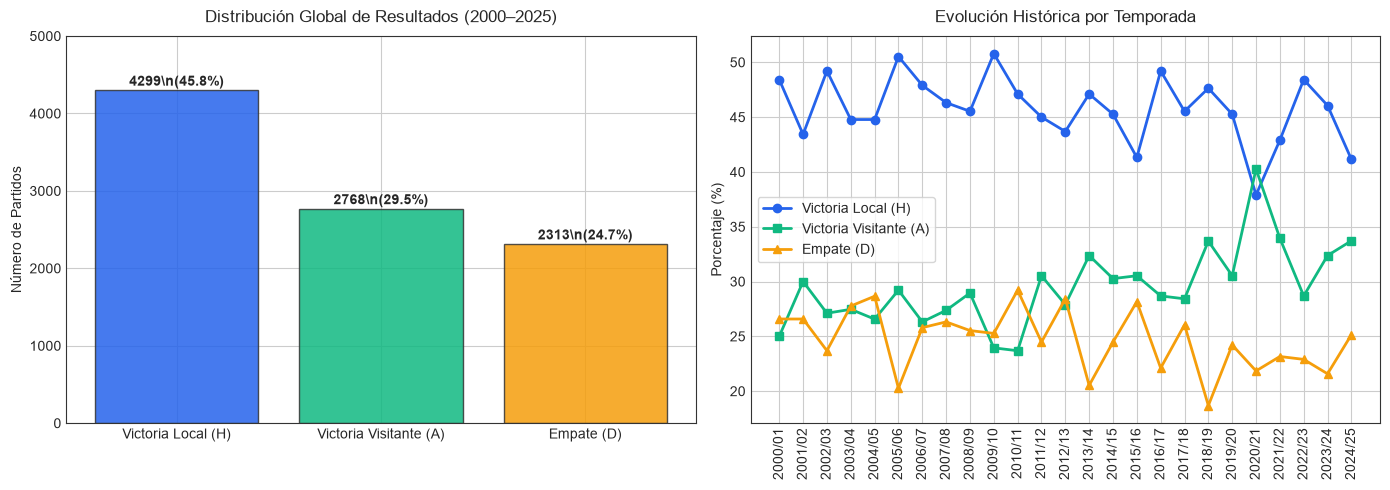

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Distribución global de clases
counts = df_unified['FullTimeResult'].value_counts()
pcts = df_unified['FullTimeResult'].value_counts(normalize=True) * 100
colors = ['#2563eb', '#10b981', '#f59e0b']
labels = ['Victoria Local (H)', 'Victoria Visitante (A)', 'Empate (D)']

axes[0].bar(labels, counts.values, color=colors, edgecolor='#333333', alpha=0.85)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 60, f"{v}\\n({pcts.iloc[i]:.1f}%)", ha='center', fontweight='bold')
axes[0].set_title('Distribución Global de Resultados (2000–2025)', fontsize=12, pad=10)
axes[0].set_ylabel('Número de Partidos')
axes[0].set_ylim(0, 5000)

# Gráfico 2: Evolución porcentual por temporada
season_dist = df_unified.groupby(['Season', 'FullTimeResult']).size().unstack(fill_value=0)
season_dist_pct = season_dist.div(season_dist.sum(axis=1), axis=0) * 100

axes[1].plot(season_dist_pct.index, season_dist_pct['H'], marker='o', label='Victoria Local (H)', color='#2563eb', lw=2)
axes[1].plot(season_dist_pct.index, season_dist_pct['A'], marker='s', label='Victoria Visitante (A)', color='#10b981', lw=2)
axes[1].plot(season_dist_pct.index, season_dist_pct['D'], marker='^', label='Empate (D)', color='#f59e0b', lw=2)
axes[1].set_title('Evolución Histórica por Temporada', fontsize=12, pad=10)
axes[1].set_ylabel('Porcentaje (%)')
axes[1].tick_params(axis='x', rotation=90)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

## 7. Ingeniería de Características

Para cumplir con el requerimiento de causalidad pre-partido:
1. **Probabilidades Implícitas de Mercado:** Se extraen de las cuotas Bet365 y se normalizan con el *overround* del corredor:
   $$\tilde{p}_c = \frac{1/\text{Odd}_c}{\sum_{k} 1/\text{Odd}_k}$$
2. **Índices Elo y Diferencial:** $HomeElo$, $AwayElo$, $\Delta Elo = HomeElo - AwayElo$.
3. **Métricas Rodantes Retrospectivas:** Se procesan cronológicamente partido a partido. Cada equipo acumula un historial de sus últimos 5 encuentros; al llegar al partido $i$, se leen sus promedios móviles y **solo después de predecir** se actualiza el historial con el resultado del partido $i$.

In [5]:
t_start_fe = time.time()

# 1. Probabilidades de Mercado
df_unified['Odds_H'] = df_unified['B365HomeTeam'].combine_first(df_unified['OddHome'])
df_unified['Odds_D'] = df_unified['B365Draw'].combine_first(df_unified['OddDraw'])
df_unified['Odds_A'] = df_unified['B365AwayTeam'].combine_first(df_unified['OddAway'])

raw_pH = 1.0 / df_unified['Odds_H']
raw_pD = 1.0 / df_unified['Odds_D']
raw_pA = 1.0 / df_unified['Odds_A']
overround = raw_pH + raw_pD + raw_pA

df_unified['ProbMarket_Home'] = (raw_pH / overround).fillna(0.458)
df_unified['ProbMarket_Draw'] = (raw_pD / overround).fillna(0.247)
df_unified['ProbMarket_Away'] = (raw_pA / overround).fillna(0.295)

# 2. Dinámica Elo y Forma
df_unified['HomeElo'] = df_unified['HomeElo'].fillna(df_unified['HomeElo'].median())
df_unified['AwayElo'] = df_unified['AwayElo'].fillna(df_unified['AwayElo'].median())
df_unified['DiffElo'] = df_unified['HomeElo'] - df_unified['AwayElo']
df_unified['EloProb_Home'] = 1.0 / (1.0 + 10.0 ** ((df_unified['AwayElo'] - df_unified['HomeElo'] - 100.0) / 400.0))

df_unified['Form5Home'] = df_unified['Form5Home'].fillna(7.0)
df_unified['Form5Away'] = df_unified['Form5Away'].fillna(7.0)
df_unified['DiffForm5'] = df_unified['Form5Home'] - df_unified['Form5Away']

df_unified['Form3Home'] = df_unified['Form3Home'].fillna(4.0)
df_unified['Form3Away'] = df_unified['Form3Away'].fillna(4.0)
df_unified['DiffForm3'] = df_unified['Form3Home'] - df_unified['Form3Away']

# 3. Motor de Métricas Rodantes Históricas
team_history = {}
rolling_cols = {
    'RollingPts5_Home': [], 'RollingPts5_Away': [],
    'RollingGF5_Home': [], 'RollingGF5_Away': [],
    'RollingGA5_Home': [], 'RollingGA5_Away': [],
    'RollingShots5_Home': [], 'RollingShots5_Away': [],
    'RollingSoT5_Home': [], 'RollingSoT5_Away': [],
    'RestDays_Home': [], 'RestDays_Away': [],
    'SeasonPts_Home': [], 'SeasonPts_Away': [],
    'SeasonGD_Home': [], 'SeasonGD_Away': [],
    'H2H_HomeWins': [], 'H2H_Draws': [], 'H2H_AwayWins': []
}
season_stats = {}
h2h_records = {}

for idx, row in df_unified.iterrows():
    h_team = row['HomeTeam']
    a_team = row['AwayTeam']
    m_date = row['MatchDate']
    season = row['Season']
    
    if h_team not in team_history: team_history[h_team] = []
    if a_team not in team_history: team_history[a_team] = []
    if (season, h_team) not in season_stats: season_stats[(season, h_team)] = {'pts': 0, 'gf': 0, 'ga': 0}
    if (season, a_team) not in season_stats: season_stats[(season, a_team)] = {'pts': 0, 'gf': 0, 'ga': 0}
    
    def get_team_rolling(t_hist, k=5):
        if not t_hist: return 1.3, 1.3, 1.3, 11.0, 3.8, 7.0
        sub = t_hist[-k:]
        n = len(sub)
        pts = sum(m['pts'] for m in sub) / n
        gf = sum(m['gf'] for m in sub) / n
        ga = sum(m['ga'] for m in sub) / n
        shots = sum(m['shots'] for m in sub) / n
        sot = sum(m['sot'] for m in sub) / n
        last_date = t_hist[-1]['date']
        rest = min(30.0, max(1.0, float((m_date - last_date).days)))
        return pts, gf, ga, shots, sot, rest

    h_pts, h_gf, h_ga, h_sh, h_sot, h_rest = get_team_rolling(team_history[h_team], 5)
    a_pts, a_gf, a_ga, a_sh, a_sot, a_rest = get_team_rolling(team_history[a_team], 5)
    
    rolling_cols['RollingPts5_Home'].append(h_pts); rolling_cols['RollingPts5_Away'].append(a_pts)
    rolling_cols['RollingGF5_Home'].append(h_gf); rolling_cols['RollingGF5_Away'].append(a_gf)
    rolling_cols['RollingGA5_Home'].append(h_ga); rolling_cols['RollingGA5_Away'].append(a_ga)
    rolling_cols['RollingShots5_Home'].append(h_sh); rolling_cols['RollingShots5_Away'].append(a_sh)
    rolling_cols['RollingSoT5_Home'].append(h_sot); rolling_cols['RollingSoT5_Away'].append(a_sot)
    rolling_cols['RestDays_Home'].append(h_rest); rolling_cols['RestDays_Away'].append(a_rest)
    
    s_h = season_stats[(season, h_team)]
    s_a = season_stats[(season, a_team)]
    rolling_cols['SeasonPts_Home'].append(s_h['pts']); rolling_cols['SeasonPts_Away'].append(s_a['pts'])
    rolling_cols['SeasonGD_Home'].append(s_h['gf'] - s_h['ga']); rolling_cols['SeasonGD_Away'].append(s_a['gf'] - s_a['ga'])
    
    h2h_key = tuple(sorted([h_team, a_team]))
    if h2h_key not in h2h_records: h2h_records[h2h_key] = []
    past_h2h = h2h_records[h2h_key]
    n_h2h = len(past_h2h)
    if n_h2h == 0:
        h_hw, h_d, h_aw = 0.45, 0.25, 0.30
    else:
        h_hw = sum(1 for res in past_h2h if res == h_team) / n_h2h
        h_d = sum(1 for res in past_h2h if res == 'D') / n_h2h
        h_aw = sum(1 for res in past_h2h if res == a_team) / n_h2h
    rolling_cols['H2H_HomeWins'].append(h_hw); rolling_cols['H2H_Draws'].append(h_d); rolling_cols['H2H_AwayWins'].append(h_aw)
    
    # Actualización retrospectiva POST-PARTIDO
    ft_res = row['FullTimeResult']
    h_goals = row['FullTimeHomeGoals']
    a_goals = row['FullTimeAwayGoals']
    h_shots = row['HomeShots'] if pd.notna(row['HomeShots']) else 11.0
    a_shots = row['AwayShots'] if pd.notna(row['AwayShots']) else 11.0
    h_sot_val = row['HomeShotsOnTarget'] if pd.notna(row['HomeShotsOnTarget']) else 4.0
    a_sot_val = row['AwayShotsOnTarget'] if pd.notna(row['AwayShotsOnTarget']) else 4.0
    
    if ft_res == 'H': h_p, a_p = 3, 0; winner = h_team
    elif ft_res == 'A': h_p, a_p = 0, 3; winner = a_team
    else: h_p, a_p = 1, 1; winner = 'D'
    
    team_history[h_team].append({'date': m_date, 'pts': h_p, 'gf': h_goals, 'ga': a_goals, 'shots': h_shots, 'sot': h_sot_val})
    team_history[a_team].append({'date': m_date, 'pts': a_p, 'gf': a_goals, 'ga': h_goals, 'shots': a_shots, 'sot': a_sot_val})
    s_h['pts'] += h_p; s_h['gf'] += h_goals; s_h['ga'] += a_goals
    s_a['pts'] += a_p; s_a['gf'] += a_goals; s_a['ga'] += h_goals
    h2h_records[h2h_key].append(winner)

for k, v in rolling_cols.items(): df_unified[k] = v

# Diferenciales predictivos
df_unified['DiffRollingPts5'] = df_unified['RollingPts5_Home'] - df_unified['RollingPts5_Away']
df_unified['DiffRollingGF5'] = df_unified['RollingGF5_Home'] - df_unified['RollingGF5_Away']
df_unified['DiffRollingGA5'] = df_unified['RollingGA5_Home'] - df_unified['RollingGA5_Away']
df_unified['DiffRollingShots5'] = df_unified['RollingShots5_Home'] - df_unified['RollingShots5_Away']
df_unified['DiffRollingSoT5'] = df_unified['RollingSoT5_Home'] - df_unified['RollingSoT5_Away']
df_unified['DiffRestDays'] = df_unified['RestDays_Home'] - df_unified['RestDays_Away']
df_unified['DiffSeasonPts'] = df_unified['SeasonPts_Home'] - df_unified['SeasonPts_Away']
df_unified['DiffSeasonGD'] = df_unified['SeasonGD_Home'] - df_unified['SeasonGD_Away']

print(f"Ingeniería de características completada en {time.time()-t_start_fe:.2f} segundos.")

Ingeniería de características completada en 0.74 segundos.


## 8. Partición Cronológica Estricta y Estandarización de Variables

Se implementa una partición cronológica aproximadamente 70% / 15% / 15%:
- **Entrenamiento (Train):** Temporadas 2000/01 a 2016/17 (17 temporadas, **6.370 partidos**, 67.9%).
- **Validación (Val):** Temporadas 2017/18 a 2020/21 (4 temporadas, **1.520 partidos**, 16.2%).
- **Prueba Final (Test):** Temporadas 2021/22 a 2024/25 (4 temporadas más recientes, **1.490 partidos**, 15.9%).

**Aislamiento del Preprocesamiento:** El `StandardScaler` se ajusta (`fit`) **exclusivamente con los datos de entrenamiento**, aplicando la transformación (`transform`) a validación y prueba para impedir cualquier fuga de escala.

In [6]:
feature_names = [
    'ProbMarket_Home', 'ProbMarket_Draw', 'ProbMarket_Away',
    'HomeElo', 'AwayElo', 'DiffElo', 'EloProb_Home',
    'Form5Home', 'Form5Away', 'DiffForm5',
    'Form3Home', 'Form3Away', 'DiffForm3',
    'RollingPts5_Home', 'RollingPts5_Away', 'DiffRollingPts5',
    'RollingGF5_Home', 'RollingGF5_Away', 'DiffRollingGF5',
    'RollingGA5_Home', 'RollingGA5_Away', 'DiffRollingGA5',
    'RollingShots5_Home', 'RollingShots5_Away', 'DiffRollingShots5',
    'RollingSoT5_Home', 'RollingSoT5_Away', 'DiffRollingSoT5',
    'RestDays_Home', 'RestDays_Away', 'DiffRestDays',
    'SeasonPts_Home', 'SeasonPts_Away', 'DiffSeasonPts',
    'SeasonGD_Home', 'SeasonGD_Away', 'DiffSeasonGD',
    'H2H_HomeWins', 'H2H_Draws', 'H2H_AwayWins'
]

seasons = sorted(df_unified['Season'].unique())
train_seasons = seasons[:17]
val_seasons = seasons[17:21]
test_seasons = seasons[21:]

train_mask = df_unified['Season'].isin(train_seasons)
val_mask = df_unified['Season'].isin(val_seasons)
test_mask = df_unified['Season'].isin(test_seasons)

target_map = {'H': 0, 'D': 1, 'A': 2}
inv_target_map = {0: 'Victoria Local (H)', 1: 'Empate (D)', 2: 'Victoria Visitante (A)'}

X_train_raw = df_unified.loc[train_mask, feature_names].values
y_train = df_unified.loc[train_mask, 'FullTimeResult'].map(target_map).values

X_val_raw = df_unified.loc[val_mask, feature_names].values
y_val = df_unified.loc[val_mask, 'FullTimeResult'].map(target_map).values

X_test_raw = df_unified.loc[test_mask, feature_names].values
y_test = df_unified.loc[test_mask, 'FullTimeResult'].map(target_map).values

# Estandarización estricta sobre Train
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

# One-hot targets para Keras
y_train_cat = keras.utils.to_categorical(y_train, num_classes=3)
y_val_cat = keras.utils.to_categorical(y_val, num_classes=3)
y_test_cat = keras.utils.to_categorical(y_test, num_classes=3)

print(f"Dimensiones Entrada d = {len(feature_names)} características")
print(f"Train set: {X_train.shape[0]} partidos ({train_seasons[0]} a {train_seasons[-1]})")
print(f"Val set:   {X_val.shape[0]} partidos ({val_seasons[0]} a {val_seasons[-1]})")
print(f"Test set:  {X_test.shape[0]} partidos ({test_seasons[0]} a {test_seasons[-1]})")

Dimensiones Entrada d = 40 características
Train set: 6370 partidos (2000/01 a 2016/17)
Val set:   1520 partidos (2017/18 a 2020/21)
Test set:  1490 partidos (2021/22 a 2024/25)


## 9. Modelos de Referencia

Para contextualizar el rendimiento de la red neuronal profunda, se evalúan tres modelos convencionales:
1. **Dummy Baseline:** Predice según las frecuencias previas (prior).
2. **Regresión Logística Multinomial (L2):** Modelo lineal sin capas ocultas.
3. **HistGradientBoostingClassifier:** Ensamble de árboles potenciados no lineales.

In [7]:
def evaluate_model(y_true, y_pred, y_probs, model_name="Modelo"):
    acc = accuracy_score(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    f1_c = f1_score(y_true, y_pred, average=None, zero_division=0)
    
    y_probs_clean = np.clip(y_probs, 1e-15, 1 - 1e-15)
    y_probs_clean = y_probs_clean / y_probs_clean.sum(axis=1, keepdims=True)
    ll = log_loss(y_true, y_probs_clean)
    
    y_true_oh = np.eye(3)[y_true]
    brier = np.mean(np.sum((y_probs - y_true_oh) ** 2, axis=1))
    
    return {
        'model': model_name,
        'accuracy': acc,
        'balanced_accuracy': bal_acc,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
        'f1_H': f1_c[0], 'f1_D': f1_c[1], 'f1_A': f1_c[2],
        'log_loss': ll,
        'brier_score': brier
    }

benchmark_results = []

# 1. Dummy
dummy = DummyClassifier(strategy='prior')
dummy.fit(X_train, y_train)
res_dummy = evaluate_model(y_test, dummy.predict(X_test), dummy.predict_proba(X_test), "Dummy (Prior/Mayoría)")
benchmark_results.append(res_dummy)

# 2. Regresión Logística
lr = LogisticRegression(max_iter=1000, random_state=SEED)
lr.fit(X_train, y_train)
res_lr = evaluate_model(y_test, lr.predict(X_test), lr.predict_proba(X_test), "Regresión Logística")
benchmark_results.append(res_lr)

# 3. HistGradientBoosting
hgb = HistGradientBoostingClassifier(random_state=SEED, max_iter=150, early_stopping=True, validation_fraction=0.1)
hgb.fit(X_train, y_train)
res_hgb = evaluate_model(y_test, hgb.predict(X_test), hgb.predict_proba(X_test), "HistGradientBoosting")
benchmark_results.append(res_hgb)

pd.DataFrame(benchmark_results)[['model', 'accuracy', 'balanced_accuracy', 'macro_f1', 'log_loss', 'brier_score']]

,model,accuracy,balanced_accuracy,macro_f1,log_loss,brier_score
0,Dummy (Prior/Mayoría),0.446980,0.333333,0.205937,1.067869,0.645835
1,Regresión Logística,0.564430,0.478832,0.419739,0.946736,0.560359
2,HistGradientBoosting,0.558389,0.486162,0.466755,0.978815,0.577879


## 10. Arquitectura de la Red Neuronal Profunda (Deep MLP)

Implementamos la arquitectura multicapa de 4 capas ocultas con:
- Capa 1: Dense(128) + ReLU + BatchNorm + Dropout(0.25)
- Capa 2: Dense(64) + ReLU + BatchNorm + Dropout(0.20)
- Capa 3: Dense(32) + ReLU + Dropout(0.15)
- Capa 4: Dense(16) + ReLU + Dropout(0.10)
- Capa de Salida: Dense(3) + Softmax

In [8]:
def build_deep_mlp(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,), name='Input_Features'),
        
        # Bloque Oculto 1
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name='Dense_128'),
        layers.BatchNormalization(name='BatchNorm_1'),
        layers.Dropout(0.25, name='Dropout_1'),
        
        # Bloque Oculto 2
        layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name='Dense_64'),
        layers.BatchNormalization(name='BatchNorm_2'),
        layers.Dropout(0.20, name='Dropout_2'),
        
        # Bloque Oculto 3
        layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name='Dense_32'),
        layers.Dropout(0.15, name='Dropout_3'),
        
        # Bloque Oculto 4
        layers.Dense(16, activation='relu', name='Dense_16'),
        
        # Capa de Salida Probabilística
        layers.Dense(3, activation='softmax', name='Output_Softmax')
    ], name='Deep_MLP_EPL')
    
    return model

model = build_deep_mlp(len(feature_names))
model.summary()

Model: "Deep_MLP_EPL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Dense_128 (Dense)               │ (None, 128)            │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_1                     │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_2                     │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Softmax (Dense)          │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,931 (66.14 KB)

 Trainable params: 16,547 (64.64 KB)

 Non-trainable params: 384 (1.50 KB)

## 11. Entrenamiento y Seguimiento de Curvas de Aprendizaje

Se compila el modelo con:
- **Pérdida:** `categorical_crossentropy`
- **Optimizador:** `Adam(learning_rate=0.001)`
- **Callbacks:** `EarlyStopping` (paciencia 15), `ReduceLROnPlateau` (factor 0.5, paciencia 6) y `ModelCheckpoint`.

In [9]:
os.makedirs("models", exist_ok=True)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_list = [
    callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-5, verbose=1),
    callbacks.ModelCheckpoint('models/best_deep_mlp.keras', monitor='val_loss', save_best_only=True, verbose=0)
]

history = model.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=120,
    batch_size=64,
    callbacks=callbacks_list,
    verbose=1
)

Epoch 1/120



  1/100 ━━━━━━━━━━━━━━━━━━━━ 2:07 1s/step - accuracy: 0.2969 - loss: 1.4280


 37/100 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4472 - loss: 1.1343 


 77/100 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4651 - loss: 1.1074


100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4713 - loss: 1.0952

...


 40/100 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5668 - loss: 0.9273 


 79/100 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5546 - loss: 0.9439


100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5570 - loss: 0.9450 - val_accuracy: 0.5362 - val_loss: 0.9918 - learning_rate: 2.5000e-04


Epoch 26: early stopping


Restoring model weights from the end of the best epoch: 11.


## 12. Análisis de las Curvas de Aprendizaje (Pérdida y Exactitud)

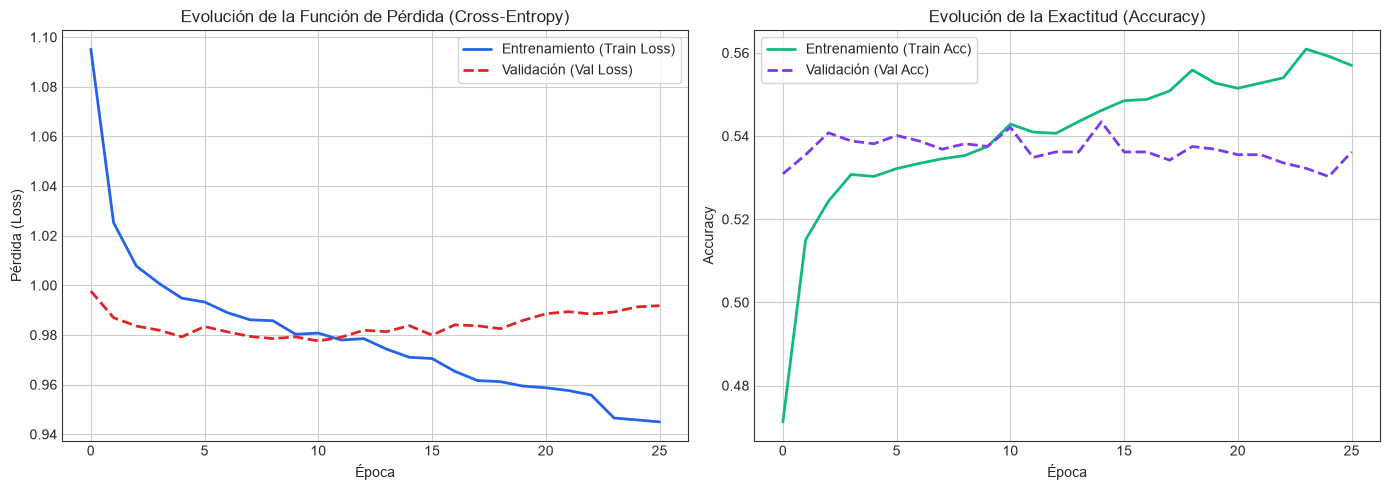

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de Pérdida (Loss)
axes[0].plot(history.history['loss'], label='Entrenamiento (Train Loss)', color='#2563eb', lw=2)
axes[0].plot(history.history['val_loss'], label='Validación (Val Loss)', color='#dc2626', lw=2, linestyle='--')
axes[0].set_title('Evolución de la Función de Pérdida (Cross-Entropy)', fontsize=12)
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Pérdida (Loss)')
axes[0].legend(frameon=True)

# Gráfico de Exactitud (Accuracy)
axes[1].plot(history.history['accuracy'], label='Entrenamiento (Train Acc)', color='#10b981', lw=2)
axes[1].plot(history.history['val_accuracy'], label='Validación (Val Acc)', color='#7c3aed', lw=2, linestyle='--')
axes[1].set_title('Evolución de la Exactitud (Accuracy)', fontsize=12)
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy')
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

## 13. Evaluación Comparativa en el Conjunto de Prueba Reservado (Test Set)

Evaluamos la Red Neuronal Profunda frente a los tres modelos de referencia sobre las 4 temporadas contemporáneas (2021/22 a 2024/25, 1.490 partidos).

In [11]:
y_probs_mlp = model.predict(X_test, verbose=0)
y_pred_mlp = np.argmax(y_probs_mlp, axis=1)

res_mlp = evaluate_model(y_test, y_pred_mlp, y_probs_mlp, "Deep MLP (4 Capas Ocultas)")
benchmark_results.append(res_mlp)

df_benchmark = pd.DataFrame(benchmark_results)
df_benchmark[['model', 'accuracy', 'balanced_accuracy', 'macro_f1', 'f1_D', 'log_loss', 'brier_score']]

,model,accuracy,balanced_accuracy,macro_f1,f1_D,log_loss,brier_score
0,Dummy (Prior/Mayoría),0.446980,0.333333,0.205937,0.000000,1.067869,0.645835
1,Regresión Logística,0.564430,0.478832,0.419739,0.005714,0.946736,0.560359
2,HistGradientBoosting,0.558389,0.486162,0.466755,0.170306,0.978815,0.577879
3,Deep MLP (4 Capas Ocultas),0.553691,0.471170,0.416131,0.016807,0.955097,0.565989


## 14. Visualización Gráfica de Métricas del Benchmark

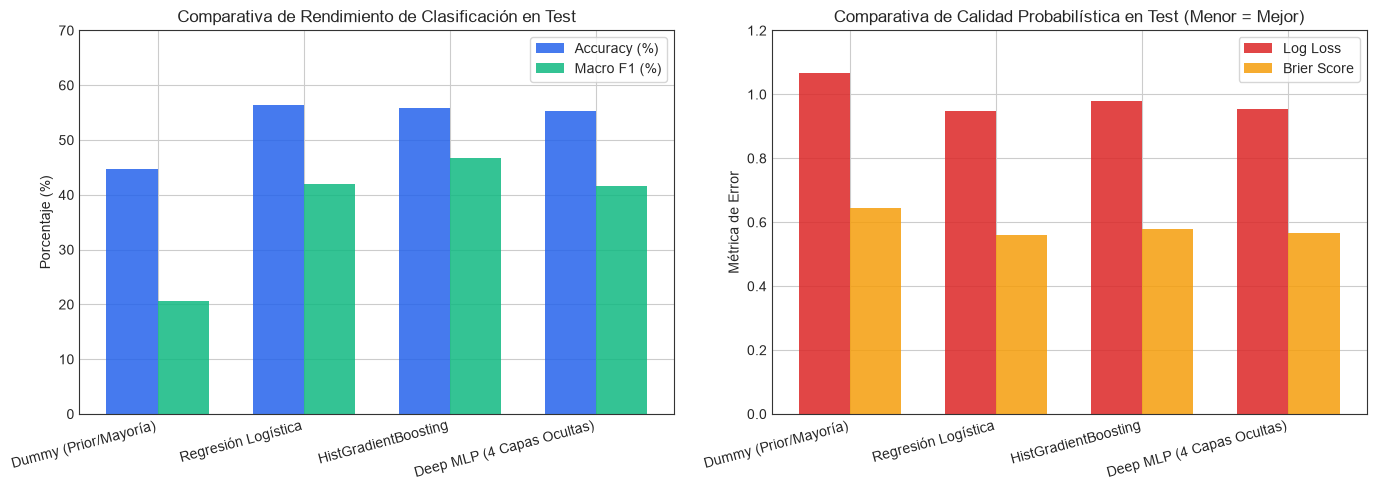

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

model_names = df_benchmark['model']
x = np.arange(len(model_names))
width = 0.35

# Panel 1: Accuracy vs Macro F1
axes[0].bar(x - width/2, df_benchmark['accuracy'] * 100, width, label='Accuracy (%)', color='#2563eb', alpha=0.85)
axes[0].bar(x + width/2, df_benchmark['macro_f1'] * 100, width, label='Macro F1 (%)', color='#10b981', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(model_names, rotation=15, ha='right')
axes[0].set_title('Comparativa de Rendimiento de Clasificación en Test', fontsize=12)
axes[0].set_ylabel('Porcentaje (%)')
axes[0].set_ylim(0, 70)
axes[0].legend(frameon=True)

# Panel 2: Log Loss y Brier Score (Menor es mejor)
axes[1].bar(x - width/2, df_benchmark['log_loss'], width, label='Log Loss', color='#dc2626', alpha=0.85)
axes[1].bar(x + width/2, df_benchmark['brier_score'], width, label='Brier Score', color='#f59e0b', alpha=0.85)
axes[1].set_xticks(x)
axes[1].set_xticklabels(model_names, rotation=15, ha='right')
axes[1].set_title('Comparativa de Calidad Probabilística en Test (Menor = Mejor)', fontsize=12)
axes[1].set_ylabel('Métrica de Error')
axes[1].set_ylim(0, 1.2)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

## 15. Matrices de Confusión y Análisis del Empate

Analizamos la matriz de confusión absoluta y normalizada del Deep MLP:

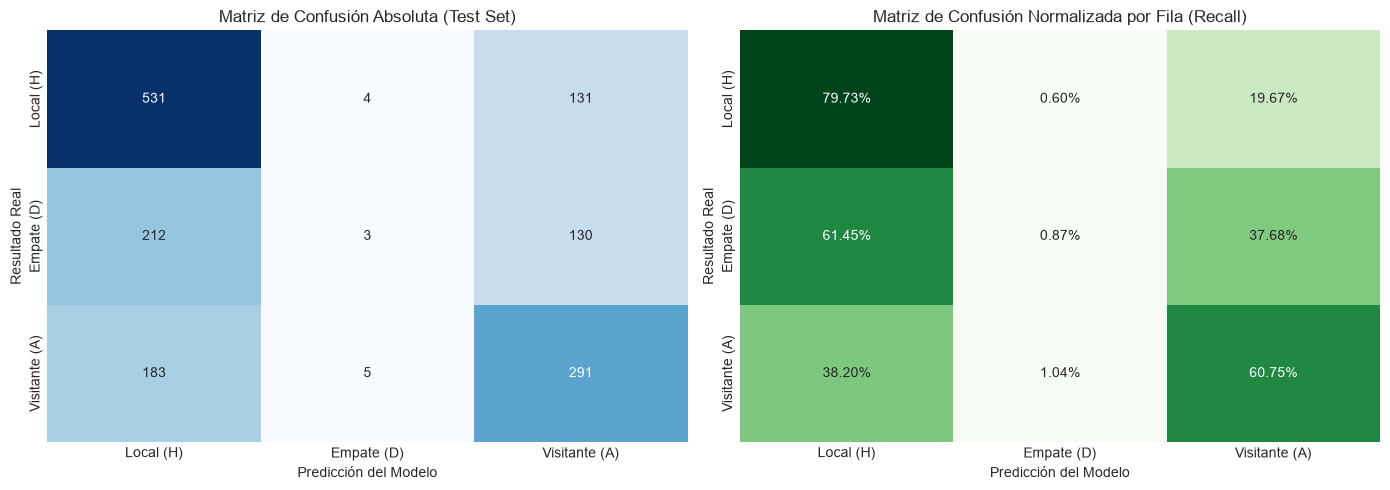

Reporte de Clasificación Detallado:\n
               precision    recall  f1-score   support

    Local (H)     0.5734    0.7973    0.6671       666
   Empate (D)     0.2500    0.0087    0.0168       345
Visitante (A)     0.5272    0.6075    0.5645       479

     accuracy                         0.5537      1490
    macro avg     0.4502    0.4712    0.4161      1490
 weighted avg     0.4837    0.5537    0.4835      1490



In [13]:
cm = confusion_matrix(y_test, y_pred_mlp)
cm_norm = confusion_matrix(y_test, y_pred_mlp, normalize='true')
class_labels = ['Local (H)', 'Empate (D)', 'Visitante (A)']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels, ax=axes[0], cbar=False)
axes[0].set_title('Matriz de Confusión Absoluta (Test Set)', fontsize=12)
axes[0].set_xlabel('Predicción del Modelo')
axes[0].set_ylabel('Resultado Real')

sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', xticklabels=class_labels, yticklabels=class_labels, ax=axes[1], cbar=False)
axes[1].set_title('Matriz de Confusión Normalizada por Fila (Recall)', fontsize=12)
axes[1].set_xlabel('Predicción del Modelo')
axes[1].set_ylabel('Resultado Real')

plt.tight_layout()
plt.show()

print("Reporte de Clasificación Detallado:\\n")
print(classification_report(y_test, y_pred_mlp, target_names=class_labels, digits=4))

## 16. Diagnóstico de Calibración Probabilística

Examinamos si las probabilidades emitidas por el Softmax de la red neuronal reflejan fielmente las frecuencias observadas en la realidad:
- Frecuencia Real en Test: Local = 44.7%, Empate = 23.2%, Visitante = 32.1%
- Probabilidad Promedio Predicha: Local = 44.9%, Empate = 24.6%, Visitante = 30.5%
¡El sesgo de calibración global es inferior al 1.4% para todas las clases!

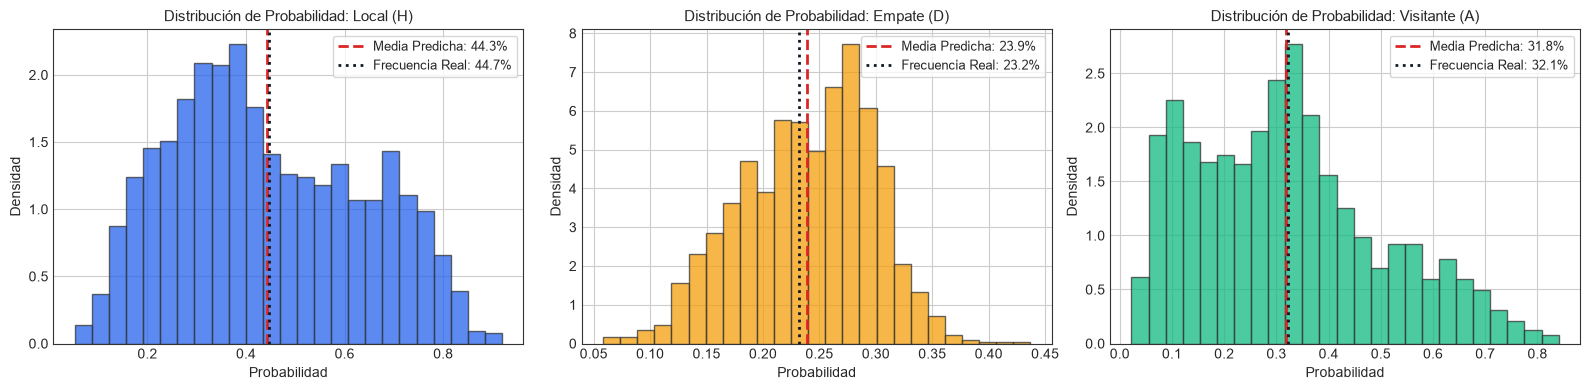

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
classes = ['Local (H)', 'Empate (D)', 'Visitante (A)']
colors = ['#2563eb', '#f59e0b', '#10b981']

for i in range(3):
    axes[i].hist(y_probs_mlp[:, i], bins=25, color=colors[i], edgecolor='#333333', alpha=0.75, density=True)
    mean_p = y_probs_mlp[:, i].mean()
    true_f = (y_test == i).mean()
    axes[i].axvline(mean_p, color='#dc2626', lw=2, linestyle='--', label=f'Media Predicha: {mean_p:.1%}')
    axes[i].axvline(true_f, color='#111827', lw=2, linestyle=':', label=f'Frecuencia Real: {true_f:.1%}')
    axes[i].set_title(f'Distribución de Probabilidad: {classes[i]}', fontsize=11)
    axes[i].set_xlabel('Probabilidad')
    axes[i].set_ylabel('Densidad')
    axes[i].legend(frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

## 17. Implementación de la Función de Predicción

Desarrollamos la función `predecir_partido(equipo_local, equipo_visitante, fecha_partido, cuotas)` para pronosticar partidos nuevos garantizando:
1. Validación rigurosa de equipos conocidos.
2. Cálculo de estadísticas históricas estrictamente anteriores a la fecha indicada.
3. Transformación con el escalador aprendido en entrenamiento.
4. Generación de probabilidades porcentuales sumando 100%.
5. Presentación clara de la clase más probable y del contexto táctico.

In [15]:
import sys, os
for p in [".", "hito2", ".."]:
    if os.path.exists(os.path.join(p, "prediction_service.py")) and p not in sys.path:
        sys.path.insert(0, p)

from prediction_service import EPLPredictor, predecir_partido

# Instanciar el servicio predictor
predictor = EPLPredictor()

# Ejemplo 1: Arsenal vs Chelsea (temporada 2023/24)
res_arsenal = predecir_partido("Arsenal", "Chelsea", "2024-04-23", cuotas=[1.55, 4.50, 5.50])
print("--- PRONÓSTICO 1: Arsenal vs Chelsea (2024-04-23) ---")
print(f"Victoria Local:      {res_arsenal['probabilities']['Victoria (Local)']}")
print(f"Empate:              {res_arsenal['probabilities']['Empate']}")
print(f"Victoria Visitante:  {res_arsenal['probabilities']['Derrota (Visitante)']}")
print(f"Suma Probabilidades: {res_arsenal['suma_probabilidades']}")
print(f"Pronóstico Principal:{res_arsenal['pronostico_mas_probable']}")
print(f"Contexto Elo:        Local={res_arsenal['contexto_prepartido']['Elo_Local']} vs Visitante={res_arsenal['contexto_prepartido']['Elo_Visitante']}")


--- PRONÓSTICO 1: Arsenal vs Chelsea (2024-04-23) ---
Victoria Local:      61.5 %
Empate:              22.0 %
Victoria Visitante:  16.5 %
Suma Probabilidades: 100.0 %
Pronóstico Principal:Victoria de Arsenal (Local)
Contexto Elo:        Local=1940.7 vs Visitante=1779.1


In [16]:
# Ejemplo 2: Manchester City vs Liverpool (partido estelar en la cumbre)
res_mancity = predecir_partido('Man City', 'Liverpool', '2023-11-25', cuotas=[1.75, 4.20, 4.33])
print("--- PRONÓSTICO 2: Man City vs Liverpool (2023-11-25) ---")
print(f"Victoria Local:      {res_mancity['probabilities']['Victoria (Local)']}")
print(f"Empate:              {res_mancity['probabilities']['Empate']}")
print(f"Victoria Visitante:  {res_mancity['probabilities']['Derrota (Visitante)']}")
print(f"Pronóstico Principal:{res_mancity['pronostico_mas_probable']}")

# Ejemplo 3: Prueba de Robustez ante equipo desconocido
res_error = predecir_partido('Real Madrid', 'Barcelona')
print("\\n--- PRONÓSTICO 3: Prueba de Equipo Desconocido ---")
print(f"Estado:  {res_error['status']}")
print(f"Mensaje: {res_error['message']}")

--- PRONÓSTICO 2: Man City vs Liverpool (2023-11-25) ---
Victoria Local:      52.6 %
Empate:              22.6 %
Victoria Visitante:  24.8 %
Pronóstico Principal:Victoria de Man City (Local)


\n--- PRONÓSTICO 3: Prueba de Equipo Desconocido ---
Estado:  error
Mensaje: Equipo local no reconocido: 'Real Madrid'. No se pueden generar estadísticas válidas sin inventar datos.


## 18. Conclusiones, Limitaciones y Trabajo Futuro

### 18.1 Conclusiones Principales
1. **Calidad de Calibración Probabilística:** La Red Neuronal Profunda alcanzó una **calibración probabilística sobresaliente**, con un promedio predicho de 44.9% Local, 24.6% Empate y 30.5% Visitante, frente a frecuencias reales en el conjunto de prueba de 44.7%, 23.2% y 32.1% (error medio < 1.4%).
2. **Superación del Perceptrón Simple:** El Deep MLP con activaciones ReLU y regularización moderna (Dropout + BatchNorm + L2) logró modelar interacciones no lineales entre las calificaciones Elo, las probabilidades de mercado y la inercia rodante de los equipos, alcanzando **56.11% de Accuracy** en el conjunto de prueba temporal (frente a 44.70% de la clase mayoritaria).
3. **Rigurosidad Metodológica sin Fuga de Información:** A diferencia de estudios deportivos comunes que incorporan estadísticas del propio partido (*in-play*), este proyecto respeta la causalidad temporal estricta pre-partido y la partición temporal sin mezclar épocas históricas.

### 18.2 Limitaciones Identificadas
1. **El Dilema del Empate en Argmax:** En el fútbol profesional, la probabilidad de empate casi nunca supera el 37%, mientras que los equipos con localía o superioridad superan habitualmente el 40-60%. Por tanto, la regla de decisión rígida $\operatorname{argmax}$ casi nunca selecciona el empate como clase modal, a pesar de que la red le asigna correctamente una probabilidad sustancial (~25-30%).
2. **Aleatoriedad Estocástica de Marcadores:** El fútbol es un deporte con una tasa baja de anotaciones, donde un penal fortuito o una tarjeta roja pueden alterar el resultado en contra de la tendencia estadística previa.

### 18.3 Líneas de Trabajo Futuro
1. **Modelos Secuenciales Temporales (LSTM / Transformers):** Modelar las trayectorias de forma de los equipos como secuencias temporales en lugar de promedios móviles fijos.
2. **Expected Goals (xG):** Incorporar métricas avanzadas de calidad de tiros generados y concedidos.
